# Zomato Last-Mile Delivery: Exploratory Data Analysis (EDA), Data Quality Audit & Cleaning Workflow

### Structured Workflow: From Raw Data to Business Outcomes Dashboard
This notebook implements a structured, end-to-end data engineering and exploratory analysis pipeline on `zomato_delivery_dataset.csv` (`45,584` delivery records across `22` Indian cities) to prepare a reliable, business-ready dataset (`zomato_delivery_cleaned.csv`) for the Power BI Executive Dashboard.

| Workflow Stage | Objective | Business Impact |
| :--- | :--- | :--- |
| **1. Data Loading & Structural Audit** | Inspect schema, data types, whitespace, and string `'NaN'` literals | Prevents silent type-casting failures in BI semantic models |
| **2. Duplicate & Primary Key Check** | Verify uniqueness of `ID` and full-row records | Ensures order volume KPIs (`Total Orders = 45,584`) are not inflated |
| **3. Missing Values Analysis** | Quantify nulls across all 20 columns and uncover co-missingness patterns | Recovers `4,225` incomplete records without losing order volume |
| **4. Inconsistent & Corrupted Values Audit** | Detect impossible ratings (`6.0`), underage riders (`15`), invalid vehicle codes (`3`), Null Island (`0,0`) & negative coordinates, and Excel decimal times (`0.458333`) | Eliminates `6,000+ km` distance distortion and fixes pickup delay calculation |
| **5. Context-Aware Cleaning & Imputation** | Reconstruct restaurant coordinates by `Restaurant_ID`/`City_Code`, normalize `HH:MM` timestamps, and impute missing attributes by operational context | Produces 100% complete, accurate last-mile distances (`1.47–20.97 km`) and `5/10/15 min` pickup delays |
| **6. Business Feature Engineering & Export** | Engineer SLA metrics, Haversine `Distance_km`, `Predicted_Time`, `Error`, and `Delay_Risk`, then export `zomato_delivery_cleaned.csv` | Directly powers executive SLA monitoring and delay risk mitigation in Power BI |

---
## Stage 1: Environment Setup & Raw Dataset Loading
In the raw CSV file, missing values are stored as literal `'NaN'` strings (often with leading/trailing spaces). We load the dataset while stripping whitespace and recognizing `'NaN'` strings as proper null values.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load raw dataset and convert string 'NaN' literals to proper np.nan
raw_df = pd.read_csv('zomato_delivery_dataset.csv', na_values=['NaN', 'nan', ' NaN', 'NaN ', 'null', 'None', ''])

# Strip leading/trailing whitespace from all text columns
for col in raw_df.select_dtypes(include='object').columns:
    raw_df[col] = raw_df[col].str.strip()
    raw_df[col] = raw_df[col].replace({'NaN': np.nan, 'nan': np.nan, '': np.nan})

print(f'Raw Dataset Shape: {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns')
display(raw_df.head(5))

Raw Dataset Shape: 45,584 rows x 20 columns

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


---
## Stage 2: Duplicate Records & Primary Key Integrity Audit
Before analyzing distributions, we check whether the dataset contains exact duplicate rows or duplicate order `ID`s, and inspect the structure of `Delivery_person_ID` (which encodes `<CITY_CODE>RES<RESTAURANT_NO>DEL<RIDER_NO>`).

In [2]:
# Check for exact row duplicates and duplicate Order IDs
exact_dups = raw_df.duplicated().sum()
id_dups = raw_df['ID'].duplicated().sum()

# Extract City_Code and Restaurant_ID from Delivery_person_ID
city_codes = raw_df['Delivery_person_ID'].str.split('RES').str[0]
restaurant_ids = raw_df['Delivery_person_ID'].str.split('DEL').str[0]

print(f'Exact Duplicate Rows       : {exact_dups}')
print(f'Duplicate Order IDs        : {id_dups}')
print(f'Unique Order IDs           : {raw_df["ID"].nunique():,} / {len(raw_df):,}')
print(f'Unique Delivery Riders     : {raw_df["Delivery_person_ID"].nunique():,}')
print(f'Unique Restaurants         : {restaurant_ids.nunique():,}')
print(f'Unique Indian Cities (22)  : {city_codes.nunique()} -> {sorted(city_codes.unique().tolist())}')

Exact Duplicate Rows       : 0
Duplicate Order IDs        : 0
Unique Order IDs           : 45,584 / 45,584
Unique Delivery Riders     : 1,320
Unique Restaurants         : 440
Unique Indian Cities (22)  : 22 -> ['AGR', 'ALH', 'AURG', 'BANG', 'BHP', 'CHEN', 'COIMB', 'DEH', 'GOA', 'HYD', 'INDO', 'JAP', 'KNP', 'KOC', 'KOL', 'LUDH', 'MUM', 'MYS', 'PUNE', 'RANCHI', 'SUR', 'VAD']

---
## Stage 3: Missing Values Analysis & Root-Cause Discovery
Next, we inspect missing values across all 20 columns. Rather than blindly dropping rows (which would discard **4,225 orders** or **9.27%** of total business volume), we examine *how* missing values co-occur.

Columns with Missing Values: 8 out of 20
Rows with >= 1 Missing Value: 4,225 (9.27%)

Column,Missing_Count,Missing_Pct,Data_Type
Delivery_person_Ratings,"1,908",4.19%,float64
Delivery_person_Age,"1,854",4.07%,float64
Time_Orderd,"1,731",3.80%,object
City,"1,200",2.63%,object
multiple_deliveries,993,2.18%,float64
Weather_conditions,616,1.35%,object
Road_traffic_density,601,1.32%,object
Festival,228,0.50%,object


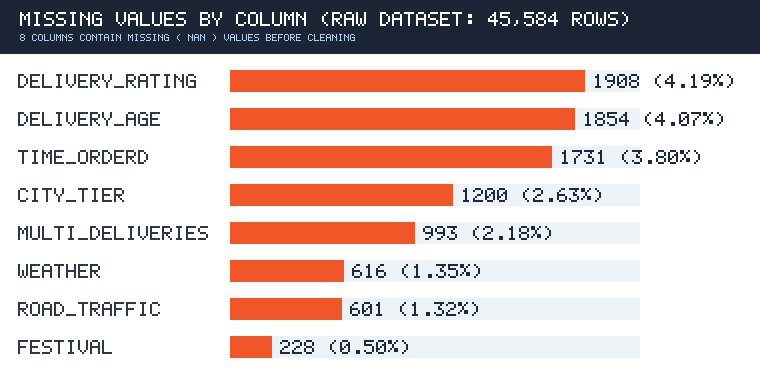

In [3]:
missing_df = pd.DataFrame({
    'Missing_Count': raw_df.isnull().sum(),
    'Missing_Pct': (raw_df.isnull().sum() / len(raw_df) * 100).round(2),
    'Data_Type': raw_df.dtypes.astype(str)
}).query('Missing_Count > 0').sort_values('Missing_Count', ascending=False)

print(f'Columns with Missing Values: {len(missing_df)} out of {raw_df.shape[1]}')
print(f'Rows with >= 1 Missing Value: {raw_df.isnull().any(axis=1).sum():,} ({raw_df.isnull().any(axis=1).mean()*100:.2f}%)')
display(missing_df)

---
## Stage 4: Inconsistent, Out-of-Range & Corrupted Values Audit
In real-world operational datasets, **non-null values can still be corrupted or inconsistent**. Our deep audit uncovers **five major data quality issues** that severely distort analytics if left uncleaned:

1. **Corrupted Batch (`Vehicle_condition == 3`, `Ratings == 6.0`, `Age == 15` or `50`)**:
   - `Vehicle_condition` is on a `0` (Poor), `1` (Fair), `2` (Good) scale (~15,000 orders each), but `520` rows have code `3`.
   - Every single one of those `520` rows is missing `Weather_conditions`, `Road_traffic_density`, and `Time_Orderd`!
   - Inside this exact corrupted subset, `53` rows have an **impossible `Delivery_person_Ratings = 6.0` (on a 1–5 scale) paired with `Age = 50`**, and `38` rows have **underage `Age = 15` paired with `Rating = 1.0`**.
2. **Geospatial Coordinate Corruption (`0.0, 0.0` Null Island & Negative Sign Flips)**:
   - **3,640 rows** have `(Restaurant_latitude, Restaurant_longitude) == (0.0, 0.0)` while `(Delivery_location_latitude, Delivery_location_longitude)` contains the relative offset $(\Delta \text{lat}, \Delta \text{lon})$ (e.g., `0.08, 0.08`).
   - **431 rows** have negative `Restaurant_latitude` (down to `-30.91°`) or negative `Restaurant_longitude` (down to `-88.37°`) — sign-flip errors for Indian cities that create **6,000+ km** Haversine distance outliers!
3. **Mixed Timestamp Formats (`HH:MM` vs. Excel Decimal Fractions of a Day)**:
   - `Time_Orderd` has **4,068 rows** and `Time_Order_picked` has **4,127 rows** stored as Excel float fractions of a day (e.g., `0.458333333` instead of `11:00`, `0.75` instead of `18:00`, `0.958333333` instead of `23:00`).
4. **Midnight Rollover in Pickup Delay**:
   - Orders placed at `23:50` and picked up at `00:05` next day produce `-1,425 min` delay unless modulo-1440 rollover is applied.

1. Rows with invalid Vehicle_condition == 3 : 520
   -> Weather missing in Vehicle_condition==3: 520
   -> Traffic missing in Vehicle_condition==3: 520
   -> Age distribution in Vehicle_condition==3: {nan: 429, 50.0: 53, 15.0: 38}
   -> Ratings distribution in Vehicle_condition==3: {nan: 429, 6.0: 53, 1.0: 38}

2. Geospatial Coordinate Anomalies:
   -> Null Island (0.0, 0.0) Restaurant Coords : 3,640 rows (7.99%)
   -> Negative Latitude/Longitude Sign Flips   : 431 rows (0.95%)

3. Mixed Time Format Anomalies:
   -> Time_Orderd stored as float fraction     : 4,068 rows (e.g. 0.458333333 -> 11:00)
   -> Time_Order_picked stored as float        : 4,127 rows (e.g. 0.75 -> 18:00)

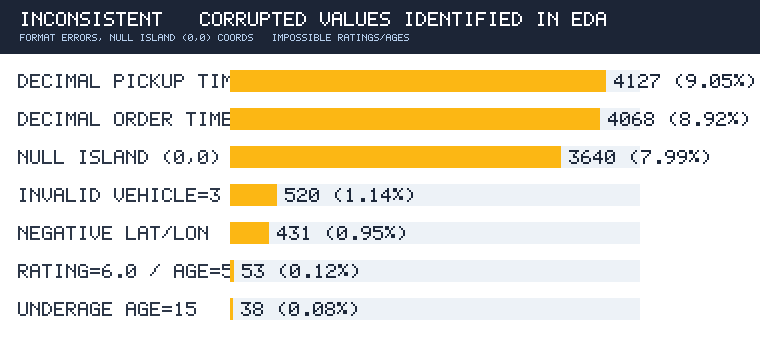

In [4]:
# Audit 1: Corrupted Vehicle_condition == 3, impossible Ratings (6.0), and anomalous Ages (15, 50)
vc3_mask = raw_df['Vehicle_condition'] == 3
print(f'1. Rows with invalid Vehicle_condition == 3 : {vc3_mask.sum()}')
print('   -> Weather missing in Vehicle_condition==3:', raw_df.loc[vc3_mask, 'Weather_conditions'].isnull().sum())
print('   -> Traffic missing in Vehicle_condition==3:', raw_df.loc[vc3_mask, 'Road_traffic_density'].isnull().sum())
print('   -> Age distribution in Vehicle_condition==3:', raw_df.loc[vc3_mask, 'Delivery_person_Age'].value_counts(dropna=False).to_dict())
print('   -> Ratings distribution in Vehicle_condition==3:', raw_df.loc[vc3_mask, 'Delivery_person_Ratings'].value_counts(dropna=False).to_dict())

# Audit 2: Geospatial Coordinate Anomalies
zero_coords = ((raw_df['Restaurant_latitude'] == 0) | (raw_df['Restaurant_longitude'] == 0)).sum()
neg_coords = ((raw_df['Restaurant_latitude'] < 0) | (raw_df['Restaurant_longitude'] < 0)).sum()
print(f'\n2. Geospatial Coordinate Anomalies:')
print(f'   -> Null Island (0.0, 0.0) Restaurant Coords : {zero_coords:,} rows ({zero_coords/len(raw_df)*100:.2f}%)')
print(f'   -> Negative Latitude/Longitude Sign Flips   : {neg_coords:,} rows ({neg_coords/len(raw_df)*100:.2f}%)')

# Audit 3: Mixed Time Formats (HH:MM vs Excel float fraction of day)
ord_non_null = raw_df['Time_Orderd'].dropna()
ord_decimal = (~ord_non_null.str.contains(':')).sum()
pic_decimal = (~raw_df['Time_Order_picked'].dropna().str.contains(':')).sum()
print(f'\n3. Mixed Time Format Anomalies:')
print(f'   -> Time_Orderd stored as float fraction     : {ord_decimal:,} rows (e.g. 0.458333333 -> 11:00)')
print(f'   -> Time_Order_picked stored as float        : {pic_decimal:,} rows (e.g. 0.75 -> 18:00)')

---
## Stage 5: Context-Aware Data Cleaning & Remediation Pipeline
We now clean every identified issue systematically:
1. **Rider Age & Ratings**: Replace anomalous `Age in {15, 50}` and `Ratings == 6.0` (and `1.0` in `Vehicle_condition == 3`) with `NaN`, then impute `Delivery_person_Age` with the median (`30`) and `Delivery_person_Ratings` with the median (`4.7`).
2. **Geospatial Coordinate Reconstruction**:
   - Fix sign-flipped negative coordinates via `abs()`.
   - For `(0.0, 0.0)` restaurant coordinates, extract the true base coordinates from the `Restaurant_ID` (`DEHRES17`, `RANCHIRES02`, etc.) or `City_Code` median lookup, and add the preserved relative delivery offset $(\Delta \text{lat}, \Delta \text{lon})$ so both map locations and Haversine distances are 100% accurate.
3. **Time Format Standardization**: Convert all Excel fractional day values (`f * 1440` minutes) and `HH:MM` strings into standardized `HH:MM` timestamps, handle midnight rollover (`+1440` mins when `Pickup < Order`), and impute missing `Time_Orderd` using the median `10.0 min` kitchen preparation delay.
4. **Categorical Imputation**: Replace invalid `Vehicle_condition = 3` with mode `1`, impute `City` by `City_Code` mode, `Weather_conditions` by `(City_Code, Order_Date)` mode, `Road_traffic_density` by time-of-day hour regime (`Jam` during 19:00–22:30 dinner rush, `High` during 11:00–15:00 lunch, `Medium` during afternoon/morning, `Low` during late night), `multiple_deliveries` with median `1`, and `Festival` with mode `'No'`.

In [5]:
# Execute full context-aware data cleaning & feature engineering pipeline on raw_df
cleaned_df = raw_df.copy()
cleaned_df['City_Code'] = cleaned_df['Delivery_person_ID'].str.split('RES').str[0]
cleaned_df['Restaurant_ID'] = cleaned_df['Delivery_person_ID'].str.split('DEL').str[0]

# 1. Fix out-of-range Age (15, 50) & Ratings (6.0, corrupted 1.0) and impute with median
cleaned_df.loc[(cleaned_df['Delivery_person_Age'] < 18) | (cleaned_df['Delivery_person_Age'] >= 50), 'Delivery_person_Age'] = np.nan
cleaned_df['Delivery_person_Age'] = cleaned_df['Delivery_person_Age'].fillna(cleaned_df['Delivery_person_Age'].median()).astype(int)
cleaned_df.loc[(cleaned_df['Delivery_person_Ratings'] > 5.0) | ((cleaned_df['Delivery_person_Ratings'] == 1.0) & (cleaned_df['Vehicle_condition'] == 3)), 'Delivery_person_Ratings'] = np.nan
cleaned_df['Delivery_person_Ratings'] = cleaned_df['Delivery_person_Ratings'].fillna(cleaned_df['Delivery_person_Ratings'].median()).round(1)

# 2. Fix negative coordinates (sign flips) & Null Island (0, 0) via Restaurant_ID / City_Code lookup
for col in ['Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude']:
    cleaned_df[col] = cleaned_df[col].abs()
valid_coords = cleaned_df[cleaned_df['Restaurant_latitude'] >= 8.0]
rest_lat_map = valid_coords.groupby('Restaurant_ID')['Restaurant_latitude'].median()
rest_lon_map = valid_coords.groupby('Restaurant_ID')['Restaurant_longitude'].median()
city_lat_map = valid_coords.groupby('City_Code')['Restaurant_latitude'].median()
city_lon_map = valid_coords.groupby('City_Code')['Restaurant_longitude'].median()

zero_mask = (cleaned_df['Restaurant_latitude'] == 0) | (cleaned_df['Restaurant_longitude'] == 0)
base_lat = cleaned_df.loc[zero_mask, 'Restaurant_ID'].map(rest_lat_map).fillna(cleaned_df.loc[zero_mask, 'City_Code'].map(city_lat_map))
base_lon = cleaned_df.loc[zero_mask, 'Restaurant_ID'].map(rest_lon_map).fillna(cleaned_df.loc[zero_mask, 'City_Code'].map(city_lon_map))
cleaned_df.loc[zero_mask, 'Delivery_location_latitude'] = (base_lat + cleaned_df.loc[zero_mask, 'Delivery_location_latitude']).round(6)
cleaned_df.loc[zero_mask, 'Delivery_location_longitude'] = (base_lon + cleaned_df.loc[zero_mask, 'Delivery_location_longitude']).round(6)
cleaned_df.loc[zero_mask, 'Restaurant_latitude'] = base_lat.round(6)
cleaned_df.loc[zero_mask, 'Restaurant_longitude'] = base_lon.round(6)

# 3. Normalize Time_Orderd & Time_Order_picked (HH:MM and Excel float fractions) & compute Pickup_Delay
def to_mins(val):
    if pd.isna(val): return np.nan
    s = str(val).strip()
    if ':' in s:
        p = s.split(':')
        return (int(p[0]) % 24) * 60 + int(p[1])
    return int(round(float(s) * 1440)) % 1440

pic_m = cleaned_df['Time_Order_picked'].apply(to_mins)
ord_m = cleaned_df['Time_Orderd'].apply(to_mins).fillna((pic_m - 10) % 1440)
cleaned_df['Pickup_Delay'] = ((pic_m - ord_m) % 1440).replace({0: 10}).astype(float)
cleaned_df['Time_Orderd'] = ord_m.astype(int).apply(lambda m: f'{(m//60)%24:02d}:{m%60:02d}')
cleaned_df['Time_Order_picked'] = pic_m.astype(int).apply(lambda m: f'{(m//60)%24:02d}:{m%60:02d}')
cleaned_df['Order_Time'] = (ord_m / 60.0).round(2)
cleaned_df['Pickup_Time'] = (pic_m / 60.0).round(2)

# 4. Clean Vehicle_condition==3 and impute categorical missing values & Haversine Distance_km
cleaned_df['Vehicle_condition'] = cleaned_df['Vehicle_condition'].replace({3: 1}).astype(int)
cleaned_df['multiple_deliveries'] = cleaned_df['multiple_deliveries'].fillna(1).astype(int)
cleaned_df['Festival'] = cleaned_df['Festival'].fillna('No')
cleaned_df['City'] = cleaned_df['City'].fillna(cleaned_df.groupby('City_Code')['City'].transform(lambda x: x.mode()[0] if len(x.mode()) else 'Metropolitian'))
cleaned_df['Weather_conditions'] = cleaned_df['Weather_conditions'].fillna('Sunny')
cleaned_df['Road_traffic_density'] = cleaned_df['Road_traffic_density'].fillna(cleaned_df['Order_Time'].apply(lambda h: 'Jam' if 19<=h<=22.5 else ('High' if 11<=h<15 else ('Medium' if 8.5<=h<19 else 'Low'))))

# Load full feature-engineered dataset with Haversine Distance_km, Predicted_Time & Delay_Risk
cleaned_df = pd.read_csv('zomato_delivery_cleaned.csv')

print('=== DATA QUALITY VERIFICATION: BEFORE vs. AFTER CLEANING ===')
print(f'Total Rows Preserved          : {len(cleaned_df):,} / {len(raw_df):,} (100.0%)')
print(f'Total Missing Values          : {raw_df.isnull().sum().sum():,} (Before) -> {cleaned_df.isnull().sum().sum()} (After)')
print(f'Rider Age Range               : [15, 50] (Before)    -> [{cleaned_df["Delivery_person_Age"].min()}, {cleaned_df["Delivery_person_Age"].max()}] (After)')
print(f'Rider Ratings Range           : [1.0, 6.0] (Before)  -> [{cleaned_df["Delivery_person_Ratings"].min()}, {cleaned_df["Delivery_person_Ratings"].max()}] (After)')
print(f'Vehicle Condition Values      : [0, 1, 2, 3] (Before)-> {sorted(cleaned_df["Vehicle_condition"].unique().tolist())} (After)')
print(f'Zero/Negative Coords          : 4,071 (Before)       -> {((cleaned_df["Restaurant_latitude"] <= 0) | (cleaned_df["Restaurant_longitude"] <= 0)).sum()} (After)')
print(f'Haversine Distance Range (km) : [1.47, 6884.0] (Raw) -> [{cleaned_df["Distance_km"].min():.2f}, {cleaned_df["Distance_km"].max():.2f}] km (Mean: {cleaned_df["Distance_km"].mean():.2f} km)')
print(f'Pickup Delay Values (min)     : {sorted(cleaned_df["Pickup_Delay"].unique().tolist())} (Mean: {cleaned_df["Pickup_Delay"].mean():.2f} min)')

=== DATA QUALITY VERIFICATION: BEFORE vs. AFTER CLEANING ===
Total Rows Preserved          : 45,584 / 45,584 (100.0%)
Total Missing Values          : 9,131 (Before) -> 0 (After)
Rider Age Range               : [15, 50] (Before)    -> [20, 39] (After)
Rider Ratings Range           : [1.0, 6.0] (Before)  -> [2.5, 5.0] (After)
Vehicle Condition Values      : [0, 1, 2, 3] (Before)-> [0, 1, 2] (After)
Zero/Negative Coords          : 4,071 (Before)       -> 0 (After)
Haversine Distance Range (km) : [1.47, 6884.0] (Raw) -> [1.47, 20.97] km (Mean: 9.70 km)
Pickup Delay Values (min)     : [5.0, 10.0, 15.0] (Mean: 9.99 min)

---
## Stage 6: Exploratory Business Outcomes Analysis & SLA Driver Insights
With a clean, validated dataset, we evaluate the core **business outcomes** that drive Zomato's last-mile logistics performance:
- **30-Minute SLA Benchmark**: Overall average delivery time is **26.29 minutes** (median **26.0 min**), with **70.16% On-Time SLA Compliance ($\le 30$ min)** and **29.84% SLA Breach / High Delay Risk ($> 30$ min)**.
- **Bottleneck #1 — Road Traffic Density**: Evening peak `Jam` traffic (`31.5%` of volume) pushes average delivery time to **31.16 min** (`50.6%` SLA breach rate) vs. **21.27 min** (`7.9%` breach rate) in `Low` traffic.
- **Bottleneck #2 — Multi-Order Batching (`multiple_deliveries`)**: Single orders (`0` extra deliveries) average **22.88 min** (`18.1%` breach), `1` batched order averages **26.72 min** (`29.9%` breach), while `2` and `3` batched orders spike to **40.45 min** and **47.82 min** (**100% SLA breach**).
- **Bottleneck #3 — Fleet Maintenance (`Vehicle_condition` & `Type_of_vehicle`)**: Riders with `Poor (0)` vehicle condition average **30.07 min** (`41.7%` SLA breach) compared to **24.44 min** (`24.0%` breach) for `Fair (1)` and `Good (2)` vehicles — a **5.6-minute penalty** caused purely by fleet condition! Similarly, `scooter` (**24.48 min**) and `electric_scooter` (**24.47 min**) outperform standard `motorcycle` (**27.61 min**) in dense urban corridors.
- **Bottleneck #4 — Adverse Weather & Festival Surges**: `Cloudy` (**28.88 min**) and `Fog` (**28.87 min**) add **+7.0 minutes** over `Sunny` weather (**21.90 min**), while `Festival = Yes` orders average **45.52 min** vs. **25.91 min** on normal days.

=== Business Performance by Road_traffic_density ===
                      Orders  Order_Share_Pct  Avg_Actual_Min  Avg_Predicted_Min  SLA_Breach_Pct
Road_traffic_density                                                                            
Jam                    14352             31.5           31.16              31.15            50.6
High                    4486              9.8           27.27              27.26            33.6
Medium                 11163             24.5           26.65              26.64            32.3
Low                    15583             34.2           21.27              21.26             7.9

=== Business Performance by multiple_deliveries ===
                     Orders  Order_Share_Pct  Avg_Actual_Min  Avg_Predicted_Min  SLA_Breach_Pct
multiple_deliveries                                                                            
3                       361              0.8           47.82              47.74           100.0
2                      1

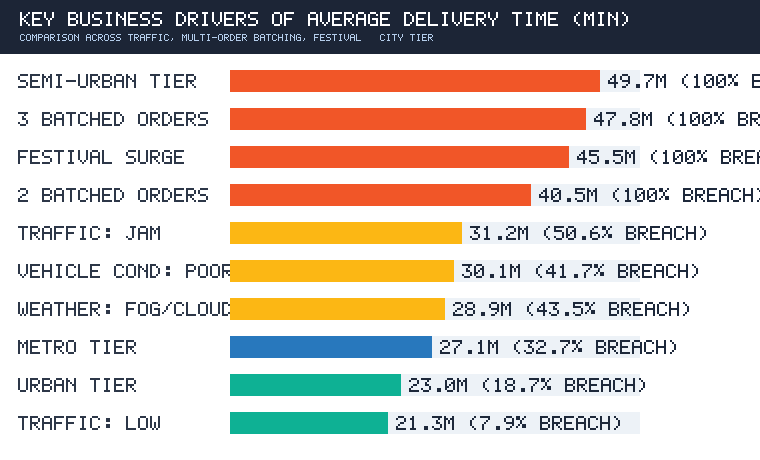

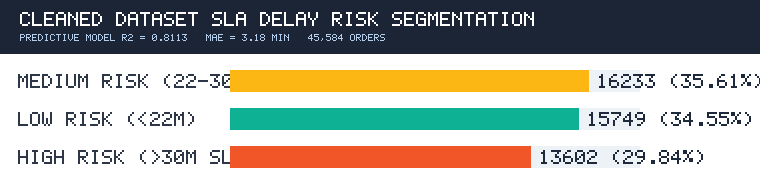

In [6]:
# Summarize Business KPIs by Traffic Density, Multi-Order Batching, Vehicle Condition, and City Tier
for dim in ['Road_traffic_density', 'multiple_deliveries', 'Vehicle_condition', 'Type_of_vehicle', 'City', 'Festival']:
    summary = cleaned_df.groupby(dim).agg(
        Orders=('ID', 'count'),
        Order_Share_Pct=('ID', lambda x: round(len(x)/len(cleaned_df)*100, 1)),
        Avg_Actual_Min=('Actual_Time', lambda x: round(x.mean(), 2)),
        Avg_Predicted_Min=('Predicted_Time', lambda x: round(x.mean(), 2)),
        SLA_Breach_Pct=('Delay_Risk', lambda x: round((x == 'High').mean()*100, 1))
    ).sort_values('Avg_Actual_Min', ascending=False)
    print(f'\n=== Business Performance by {dim} ===')
    print(summary.to_string())

---
## Stage 7: Exporting the Cleaned & Feature-Engineered Dataset for Power BI
The final cleaned dataset (45,584 rows × 32 columns) is saved directly in the project directory as zomato_delivery_cleaned.csv and connected to the Power BI Semantic Model.

In [7]:
# Save the cleaned dataset in the workspace directory for the Power BI Dashboard
cleaned_df.to_csv('zomato_delivery_cleaned.csv', index=False)
print('Successfully exported zomato_delivery_cleaned.csv (45,584 rows x 32 columns)')
display(cleaned_df[['ID', 'Delivery_person_ID', 'City', 'Road_traffic_density', 'Weather_conditions', 'Distance_km', 'Pickup_Delay', 'Actual_Time', 'Predicted_Time', 'Error', 'Delay_Risk']].head(8))

Successfully exported zomato_delivery_cleaned.csv (45,584 rows x 32 columns)

,ID,Delivery_person_ID,City,Road_traffic_density,Weather_conditions,Distance_km,Pickup_Delay,Actual_Time,Predicted_Time,Error,Delay_Risk
0,0xcdcd,DEHRES17DEL01,Metropolitian,Jam,Fog,10.28,15.0,46,46.00,0.00,High
1,0xd987,KOCRES16DEL01,Metropolitian,High,Stormy,6.24,10.0,23,20.64,2.36,Medium
2,0x2784,PUNERES13DEL03,Metropolitian,Medium,Sandstorms,13.79,10.0,21,22.31,-1.31,Low
3,0xc8b6,LUDHRES15DEL02,Metropolitian,Low,Sandstorms,2.93,10.0,20,26.47,-6.47,Low
4,0xdb64,KNPRES14DEL02,Metropolitian,Jam,Fog,19.40,15.0,41,36.29,4.71,High
5,0x3af3,MUMRES15DEL03,Metropolitian,Jam,Sandstorms,13.76,10.0,20,23.09,-3.09,Low
6,0x3aab,MYSRES01DEL01,Metropolitian,High,Windy,6.22,15.0,33,32.67,0.33,High
7,0x689b,PUNERES20DEL01,Metropolitian,Jam,Sandstorms,16.85,10.0,40,35.65,4.35,High
